# Temps d'exécution

## Un premier exemple
Ci-suit un exemple de mesure du temps d'exécution. 
Exécutez cet exemple à plusieurs reprises. 
Observez que le temps d'exécution varie mais que l'ordre de grandeur reste identique.

Vous devriez observer des variations pour l'exécution d'une même instruction et une grande différence de temps d'exécution entre les deux instructions.

In [4]:
import timeit
nb_repet = 100
temps_exec = timeit.timeit(stmt="x=1",setup="",number=nb_repet)
print(int(temps_exec/nb_repet*1000000000))

29


## Quelques explications

Le module timeit "fournit une façon simple de mesurer le temps d'exécution de fragments de code Python" [https://docs.python.org/fr/3/library/timeit.html]

Dans l'exemple d'exécution, le nom des paramètres de la fonction <code>timeit</code> (du module <code>timeit</code>) ont été conservé pour bien comprendre à quoi ils correspondent :
* <code>stmt</code> : le code dont le temps d'exécution est analysé.
* <code>number</code> : nombre de fois où le code <code>stmt</code> (la valeur retournée par <code>timeit</code> est le temps total d'exécution).
* <code>setup</code> : un code permettant de fixer le contexte (import de fonctions, de valeurs...) pour exécuter le code <code>stmt</code> (nous verrons des exemples ci-après). Important! Ce code n'est exécuté qu'une fois (quelle que soit la valeur de <code>number</code>).

La valeur retournée par <code>timeit</code> exprime un temps en seconde.

L'expression <code>int(temps_exec/nb_repet*1000000000)</code> :
* calcule le temps d'exécution moyen d'une exécution du code <code>stmt</code>
* affiche le résulat en nanosecondes (grâce à la multiplication) et sans chiffre après la virgule (grâce au changement de type)

## Adaptation pour une autre instruction
Reprenez ci-dessous l'exemple précédent avec l'instruction : <code>print("bonjour")</code> (il est conseillé de prendre une valeur petite pour <code>number</code>... vous le verrez bien en exécutant de toute manière).

In [8]:
# Mesure du temps d'exécution de l'instruction print("bonjour")
nb_repet = 10
temps_exec = timeit.timeit(stmt='print("bonjour")',setup="",number=nb_repet)
print(int(temps_exec/nb_repet*1000000000))
# Remarque : on n'a pas répété le "import timeit" car le module est déjà chargé suite à l'exécution du bloc précédent

bonjour
bonjour
bonjour
bonjour
bonjour
bonjour
bonjour
bonjour
bonjour
bonjour
6433


Observez que le temps d'exécution de cette seconde instruction est beaucoup plus grand que celui de la première instruction.

## Mesure du temps d'exécution d'un appel d'une fonction

Rappelons le code de la fonction <code>mystere2()</code> vu dans la deuxième partie sur les listes.

In [9]:
def mystere2( n ):
    """
    ????
    """
    lis = []
    for i in range(n):
        lis.append(2*i+1)
    return lis

Vérifiez que le code suivant, sans doute contre toute attente, ne fonctionne pas (Même après exécution du bloc précédent).

In [10]:
nb_repet = 100
temps_exec = timeit.timeit(stmt="mystere2(10)",setup="",number=nb_repet)
print(int(temps_exec/nb_repet*1000000000))

NameError: name 'mystere2' is not defined

*Que se passe-t-il ?*

L'environnement d'exécution de mesure mis en place par timeit est indépendant de l'environnement d'exéxcution du présent notebook. Dans cet environnement de timeit, la fonction <code>mystere2()</code> n'est pas définie.

Il faut utiliser le paramètre <code>setup</code>.

In [11]:
nb_repet = 100
temps_exec = timeit.timeit(stmt="mystere2(10)",
                           setup="from __main__ import mystere2",
                           number=nb_repet)
print(int(temps_exec/nb_repet*1000000000))

2162


Nous n'explorerons pas toutes les subtilités d'usage de <code>timeit</code> mais il semble intéressant de noter :
* Il peut y avoir plusieurs instructions dans <code>stmt</code> et dans <code>setup</code> (alors séparée par des virgules)

In [12]:
nb_repet = 100
temps_exec = timeit.timeit(stmt="lis=mystere2(val);longueur=len(lis)",
                           setup="from __main__ import mystere2;val=12",
                           number=nb_repet)
print(int(temps_exec/nb_repet*1000000000))

941


* Si le code de <code>stmt</code> ou de <code>setup</code> est un peu long, on peut les prédéfinir dans des variables textes

In [13]:
nb_repet = 100
code_a_mesurer = """
lis=mystere2(val)
longueur=len(lis)
"""
contexte = """
from __main__ import mystere2
val=12
"""
temps_exec = timeit.timeit(stmt=code_a_mesurer,
                           setup=contexte,
                           number=nb_repet)
print(int(temps_exec/nb_repet*1000000000))

2417


* Il est bien sûr possible de stocker la fonction à tester (ou des définitions de varaibles dans un fichier) et d'importer ce qu'il faut via le paramètre <code>setup</code> (attention on ne peut pas faire un <code>import *</code> et il faut être précis).

Ci-suit une autre approche un peu plus souple pour un appel de fonction.

In [14]:
nb_repet = 100
val=12
temps_exec = timeit.timeit(stmt=lambda:mystere2(val),
                           number=nb_repet)
print(int(temps_exec/nb_repet*1000000000))

2502


## Étudier la dépendance du temps d'exécution d'une fonction vis-à-vis de la valeur du paramètre
On s'attend à ce que le temps d'exécution de la fonction <code>mystere2()</code> évolue de manière linéaire par rapport à la valeur du paramètre de la fonction. Nous cherchons dans l'exercice suivant à le vérifier. Cet algorithme de construction de la liste a une complexité en temps qui est effectivement en *O(n)* où *n* est la valeur du paramètre et donc la longueur de la liste construite.

Dans un premier temps, vous allez stocker dans une liste <code>temps_mystere2</code> des temps d'exécution pour des valeurs de paramètres de plus en plus grand. Dans un deuxième temps, un code est fourni pour voir l'évolution sous forme graphique.

**Exercice.** Compléter la séquence d'instructions suivante afin de stocker dans une variable <code>temps_mystere2</code> les temps d'exécution en ns de la fonction <code>mystere2( )</code> sur des listes de longueur variant entre <code>min_len</code> et <code>max_len</code> par pas de valeur <code>pas_len</code>.

In [19]:
min_len = 1
max_len = 100000
pas_len = max_len//100
nb_repet = 10 # nombre faible pour ne pas avoir un trop grand ralentissement
    # des mesures quand la valeur du paramètre de mystère2 va grandir
# à compléter
temps_mystere2 = []
for taille in range(min_len, max_len, pas_len):
    # mesure du temps d'exécution de l'appel à mystere2 avec la valeur de taille en paramètre
    temps_exec = timeit.timeit(stmt=lambda:mystere2(taille),
                           number=nb_repet)
    temps_mystere2.append(int(temps_exec/nb_repet*1000000000))
print(temps_mystere2)

[1416, 91854, 263529, 310424, 375212, 444966, 457079, 540320, 592587, 614054, 591191, 576266, 645141, 679162, 736466, 795754, 845820, 894600, 960291, 1000966, 1055833, 1109608, 1159204, 1212125, 1260020, 1320391, 1366920, 1417775, 1465383, 1526366, 1579458, 1625450, 1688379, 1741179, 1787379, 1859812, 1891562, 1945041, 1993154, 2049208, 2114695, 2168254, 2224420, 2271683, 2328120, 2367699, 2418920, 2478933, 2530329, 2584066, 2637099, 2686183, 2728249, 2800016, 2849691, 2915858, 2987691, 3155754, 3153637, 3211195, 3256375, 3317454, 3359520, 3399475, 3506666, 3535250, 3599929, 3640354, 3706420, 3766279, 3807749, 3870658, 3922391, 3971766, 4032579, 4081983, 4122091, 4180520, 4242783, 4287287, 4346449, 4398904, 4446866, 4499962, 4511270, 4542870, 4645799, 4705683, 4762083, 4828558, 4983679, 5045162, 5096083, 5151341, 5197095, 5260970, 5306966, 5374987, 5420312, 5461920]


La séquence suivante permet de visualiser l'évolution des temps d'exécution de la fonction.

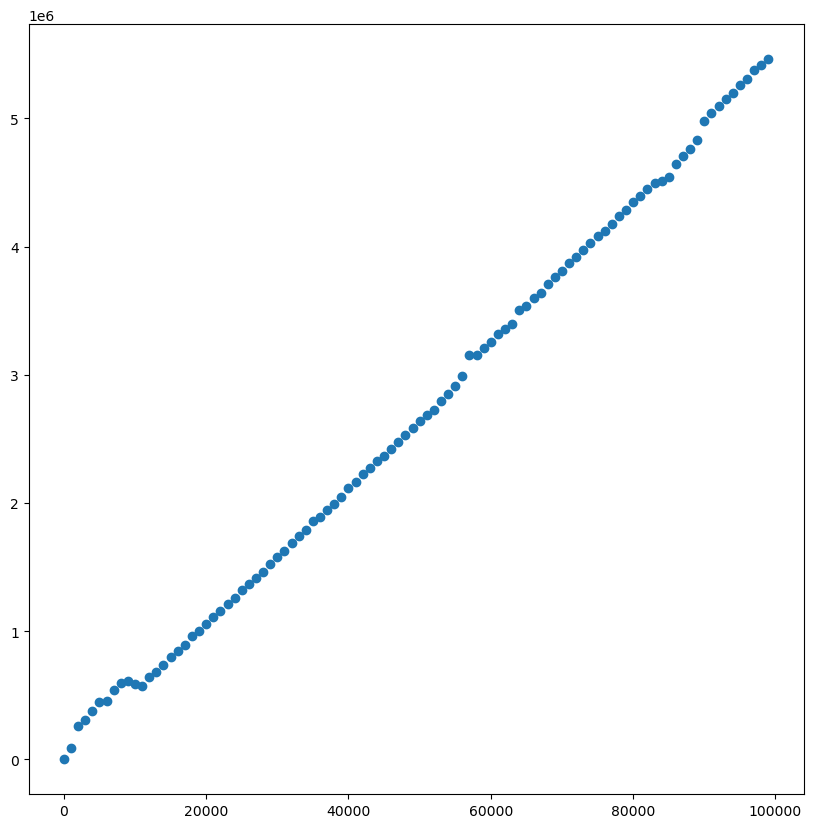

In [20]:
# La ligne suivante permet l'affichage de la visualisation
    # dans le notebook et non en fenêtre popup
%matplotlib inline  
from matplotlib import pyplot as plt 
figure = plt.figure(figsize=(10, 10))
abscisses = [ n for n in range(min_len, max_len+1, pas_len)]
plot = plt.scatter(abscisses, temps_mystere2)
plt.show()

Une droite devrait apparaître dans la visualisation (de manière approximative à cause des imprécisions de mesure inévitables).

*Suggestion.* Faites varier les valeurs de <code>max_len</code> et <code>pas_len</code> en prenant les valeurs <code>10 000</code> et <code>100</code> puis <code>100 000</code> et <code>1 000</code> puis <code>1 000 0000</code> et <code>10 000</code> (tous les couples de valeurs sont conçus pour ne faire que <code>100</code> évaluations d'exécution de fonction ; pour l'exécution du dernier couple, vous ne devriez pas avoir une exécution immédiate).

*Suggestion d'exercice.* Dans la deuxième partie sur les listes, nous avons vu une fonction <code>mystere2bis()</code> réalisant le même traitement que la fonction <code>mystere2()</code>. Cette deuxième fonction utilise des spécificités Python. Elle devrait être plus rapide que le temps d'exécution de la fonction mystere2. Modifiez les codes précédents pour permettre une vérification visuelle de cela.

**Remarque**. Vous reverrez l'utilisation de <code>timeit</code>, cette fois en ligne de commande, dans la partie assurée par Mme Bringay.